# 01 — Data Cleaning (R2)

**Project:** Birds' Species Classification · **Requirement:** R2 Data Analysis and Exploration (cleaning part)

This notebook checks the quality of both datasets and makes every cleaning decision **with evidence**.
Each section ends with a **Decision** box, which is then collected in the cleaning log at the end
(this log feeds Section 3 *Dataset Description and Analysis* of the report).

| | Dataset 1 (tabular) | Dataset 2 (images) |
|---|---|---|
| Source | CUB-200-2011 attribute annotations | CUB-200-2011 photographs |
| Rows | 11,788 images | 11,788 images |
| Inputs | 312 binary visual attributes (bill shape, wing colour, …) | RGB photo + bounding box |
| Target | species (200 classes) | species (200 classes) |

**Before running:** `python scripts/download_data.py` then `python scripts/prepare_data.py` (see README).

**Output:** `data/processed/cub_attributes_clean.csv` — the cleaned Dataset 1 used by all later notebooks and by R3/R4.

**Contents**
1. Setup
2. Integrity checks (missing values, ids, label ranges)
3. Malformed lines in the raw attribute file
4. Class balance and the train/test split (is this a long-tail problem?)
5. Hidden missing values: "not visible" attributes + experiment
6. Duplicate rows with conflicting labels
7. Rare attributes
8. Do we need scaling, normalisation or binning?
9. Dataset 2: image checks
10. Cleaning log and saving the cleaned data

## 1. Setup

In [1]:
import sys
sys.path.insert(0, "../scripts")          # so we can import our own helper modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import r2_utils as u                      # paths, plot style, loading helpers
import prepare_data as prep               # the pipeline's raw-file readers

u.set_plot_style()
pd.set_option("display.max_columns", 20)

df = u.load_attributes(clean=False)       # Dataset 1 as produced by the pipeline
images = u.load_images()                  # Dataset 2 metadata
ATTR = u.attribute_columns(df)            # the 312 attribute column names

print(f"Dataset 1: {df.shape[0]:,} rows x {df.shape[1]} columns ({len(ATTR)} attributes)")
print(f"Dataset 2: {images.shape[0]:,} rows x {images.shape[1]} columns")
df.head(3)

Dataset 1: 11,788 rows x 318 columns (312 attributes)
Dataset 2: 11,788 rows x 14 columns


,image_id,class_id,species,name_group,is_train,conflicting_duplicate,has_bill_shape::curved_(up_or_down),has_bill_shape::dagger,has_bill_shape::hooked,has_bill_shape::needle,...,has_crown_color::pink,has_crown_color::orange,has_crown_color::black,has_crown_color::white,has_crown_color::red,has_crown_color::buff,has_wing_pattern::solid,has_wing_pattern::spotted,has_wing_pattern::striped,has_wing_pattern::multi-colored
0,1,1,Black footed Albatross,Albatross,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
1,2,1,Black footed Albatross,Albatross,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,1,Black footed Albatross,Albatross,0,0,0,0,0,0,...,0,0,0,0,0,1,0,0,1,0


## 2. Integrity checks

Before anything else we check the basics covered in Lecture 3 (*Getting to know your data*):
missing values, duplicated ids, impossible values, and whether both datasets describe the same images.

In [2]:
checks = {
    "Missing values in Dataset 1":            int(df.isna().sum().sum()),
    "Missing values in Dataset 2":            int(images.isna().sum().sum()),
    "Duplicated image_id (Dataset 1)":        int(df["image_id"].duplicated().sum()),
    "Attribute values other than 0/1":        int((~df[ATTR].isin([0, 1])).sum().sum()),
    "Number of species (classes)":            df["class_id"].nunique(),
    "class_id range":                         f'{df["class_id"].min()}–{df["class_id"].max()}',
    "Same image_ids in both datasets":        set(df["image_id"]) == set(images["image_id"]),
    "Same species labels in both datasets":   bool((df.set_index("image_id")["class_id"]
                                                    == images.set_index("image_id")["class_id"]).all()),
    "Same train/test flag in both datasets":  bool((df.set_index("image_id")["is_train"]
                                                    == images.set_index("image_id")["is_train"]).all()),
}
pd.Series(checks, name="result").to_frame()

,result
Missing values in Dataset 1,0
Missing values in Dataset 2,0
Duplicated image_id (Dataset 1),0
Attribute values other than 0/1,0
Number of species (classes),200
class_id range,1–200
Same image_ids in both datasets,True
Same species labels in both datasets,True
Same train/test flag in both datasets,True


> **Decision 1 — Integrity.** No missing values, no duplicated ids, all attributes are strictly 0/1,
> and both datasets share the same 11,788 images, labels and split. Nothing needs fixing here —
> but "no missing values" turns out to be misleading (see Section 5).

## 3. Malformed lines in the raw attribute file

`attributes/image_attribute_labels.txt` should have 5 columns per line:
`<image_id> <attribute_id> <is_present> <certainty_id> <time>`.
Reading it naively with `pd.read_csv` fails, so we look at the raw lines directly.

In [3]:
from collections import Counter

field_counts = Counter()
bad_examples, bad_images = [], set()
with open(u.RAW_DIR / "attributes" / "image_attribute_labels.txt") as f:
    for line in f:
        n = len(line.split())
        field_counts[n] += 1
        if n != 5:
            bad_images.add(int(line.split()[0]))
            if len(bad_examples) < 3:
                bad_examples.append(line.rstrip())

print("Lines by number of fields:", dict(field_counts))
print("Images affected:", sorted(bad_images))
print("Examples of malformed lines:")
for line in bad_examples:
    print("   ", repr(line))

Lines by number of fields: {5: 3677250, 6: 606}
Images affected: [2275, 9364]
Examples of malformed lines:
    '2275 10 0 1 0  1.509'
    '2275 11 0 1 0  1.509'
    '2275 12 0 1 0  1.509'


> **Decision 2 — Malformed lines.** 606 lines (all from images 2275 and 9364) contain an extra `0` field.
> The pipeline (`prepare_data.load_image_attribute_labels`) reads the first four fields and the last field,
> which repairs these lines without losing any image. *(Kept: all 11,788 images.)*

## 4. Class balance and the train/test split

In the pitch Q&A the lecturer asked us to check the smallest class and justify that this is **not a long-tail problem**.
CUB-200-2011 comes with an **official train/test split** (`train_test_split.txt`), which we use for both datasets
so that tabular and image models are evaluated on exactly the same images (no leakage between them).

In [4]:
counts = (df.groupby(["class_id", "is_train"]).size()
            .unstack().rename(columns={1: "train", 0: "test"}))
counts["total"] = counts.sum(axis=1)

summary = counts.describe().loc[["min", "max", "mean", "std"]].round(1)
summary.loc["max/min ratio"] = (counts.max() / counts.min()).round(2)
display(summary)

smallest = counts.nsmallest(5, "total").join(
    df.drop_duplicates("class_id").set_index("class_id")["species"])
smallest

is_train,test,train,total
min,11.00,29.00,41.00
max,30.00,30.00,60.00
mean,29.00,30.00,58.90
std,2.90,0.20,2.90
max/min ratio,2.73,1.03,1.46


,test,train,total,species
class_id,,,,
6,11,30,41,Least Auklet
5,14,30,44,Crested Auklet
18,15,30,45,Spotted Catbird
8,18,30,48,Rhinoceros Auklet
105,19,30,49,Whip poor Will


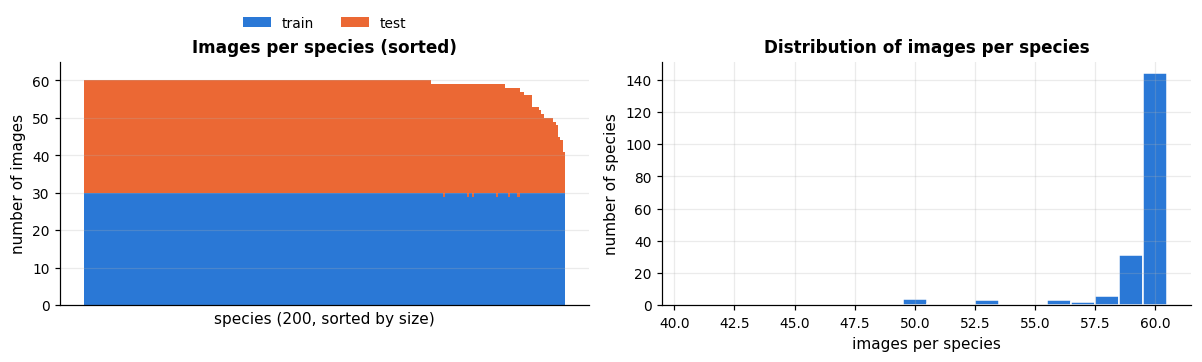

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))

# Left: images per species (sorted), split into train and test
order = counts.sort_values("total", ascending=False)
x = np.arange(len(order))
axes[0].bar(x, order["train"], width=1.0, color=u.BLUE, label="train")
axes[0].bar(x, order["test"], bottom=order["train"], width=1.0, color=u.ORANGE, label="test")
axes[0].set(title="Images per species (sorted)", xlabel="species (200, sorted by size)",
            ylabel="number of images", xticks=[])
axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, 1.08), ncols=2)
axes[0].set_ylim(0, 65)

# Right: distribution of training images per species
axes[1].hist(counts["total"], bins=np.arange(40.5, 61.5), color=u.BLUE, edgecolor="white")
axes[1].set(title="Distribution of images per species", xlabel="images per species",
            ylabel="number of species")
plt.tight_layout()
u.save_figure(fig, "01_class_balance")
plt.show()

**Figure 1** — Every species has 41–60 images (144 of 200 have exactly 60). The **training set is almost perfectly
balanced (29 or 30 images per species)**; only the test set varies (11–30), because the smallest species lose
images from the test half.

> **Decision 3 — Class balance.** This is *not* a long-tail problem: the largest/smallest ratio is only about 1.5
> overall and ~1.0 in training. We therefore **keep all 200 species and the official split, without resampling**.
> Because test-set sizes differ per species, later evaluation should report **macro-averaged** precision/recall/F1
> (every species counts equally) alongside accuracy.

## 5. Hidden missing values: "not visible" attributes

The attributes were labelled by Amazon Mechanical Turk workers, who also gave a **certainty** for each answer:

| certainty_id | meaning |
|---|---|
| 1 | not visible |
| 2 | guessing |
| 3 | probably |
| 4 | definitely |

If a part of the bird is hidden (e.g. wings folded), the worker answers "not visible" and the attribute is stored as **0**.
So a 0 can mean *"absent"* **or** *"could not be seen"* — this is a form of missing data hidden inside a dataset
that technically has no missing values.

In [6]:
labels_long = prep.load_image_attribute_labels()       # one row per image x attribute
certainty_names = {1: "not visible", 2: "guessing", 3: "probably", 4: "definitely"}

table = (labels_long.groupby("certainty_id")
         .agg(share_of_all_labels=("is_present", "size"), share_marked_present=("is_present", "mean")))
table["share_of_all_labels"] /= len(labels_long)
table.index = table.index.map(certainty_names)
table.round(3)

  attribute labels: 3,677,856 rows read, 606 malformed lines repaired


,share_of_all_labels,share_marked_present
certainty_id,,
not visible,0.107,0.000
guessing,0.062,0.120
probably,0.278,0.119
definitely,0.553,0.109


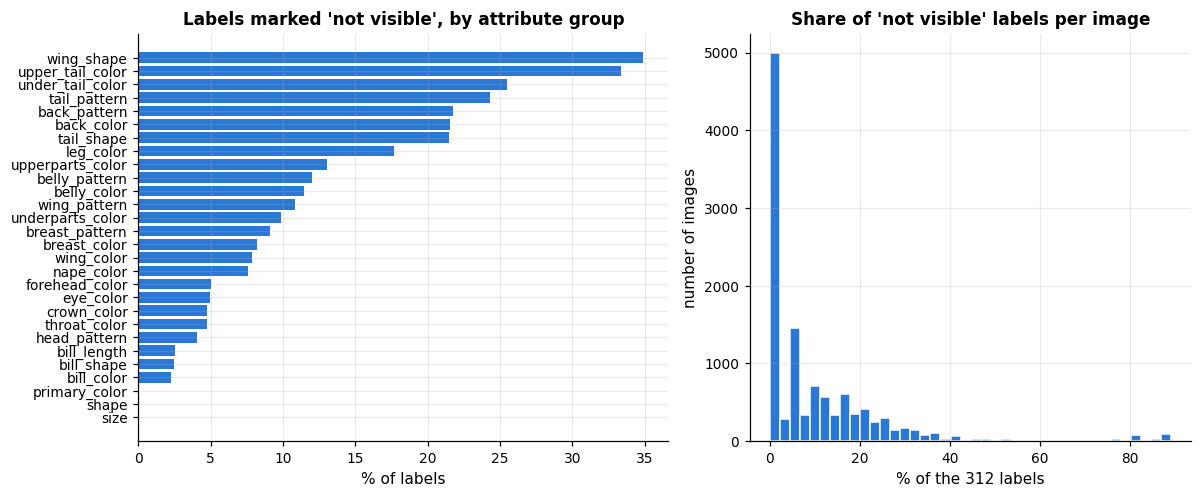

Images with more than half their attributes not visible: 353


In [7]:
labels_long["not_visible"] = labels_long["certainty_id"] == 1
labels_long["group"] = labels_long["attribute_id"].map(
    dict(enumerate([u.attribute_group(c) for c in ATTR], start=1)))

per_group = labels_long.groupby("group")["not_visible"].mean().sort_values()
per_image = labels_long.groupby("image_id")["not_visible"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
axes[0].barh(per_group.index, per_group.values * 100, color=u.BLUE)
axes[0].set(title="Labels marked 'not visible', by attribute group", xlabel="% of labels")
axes[1].hist(per_image * 100, bins=40, color=u.BLUE, edgecolor="white")
axes[1].set(title="Share of 'not visible' labels per image", xlabel="% of the 312 labels",
            ylabel="number of images")
plt.tight_layout()
u.save_figure(fig, "01_not_visible")
plt.show()

print(f"Images with more than half their attributes not visible: {(per_image > 0.5).sum()}")

**Figure 2** — 10.7% of all labels are "not visible", and these are **always stored as 0**. Wing shape is hidden in
about 35% of images, while bill and size are almost always visible. A few hundred images (birds partly hidden or
far away) have more than half of their attributes not visible.

### Experiment: should we treat "not visible" differently?

Instead of guessing, we test four ways of encoding the attributes and let the data decide.
To avoid using the test set for a data-preparation decision, we use **5-fold stratified cross-validation on the
training set only**, with three classifiers from the course (logistic regression, k-NN, decision tree) and
macro-F1 as the metric.

| Encoding | Value for present / absent / not visible |
|---|---|
| A. raw binary (as provided) | 1 / 0 / 0 |
| B. signed, unknown = 0 | +1 / −1 / 0 |
| C. signed, weighted by certainty | ±1 (definitely), ±0.75 (probably), ±0.5 (guessing), 0 (not visible) |
| D. only confident "present" counts | 1 if present *and* probably/definitely, else 0 |

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Wide matrices (rows = images, columns = attributes) of the raw labels and certainties
present = labels_long.pivot(index="image_id", columns="attribute_id", values="is_present")
certain = labels_long.pivot(index="image_id", columns="attribute_id", values="certainty_id")
weight = certain.replace({1: 0.0, 2: 0.5, 3: 0.75, 4: 1.0})
sign = present.replace({0: -1})

encodings = {
    "A. raw binary":            present,
    "B. signed, unknown = 0":   sign.where(certain != 1, 0),
    "C. certainty-weighted":    sign * weight,
    "D. confident present only": ((present == 1) & (certain >= 3)).astype(int),
}

train_ids = df.loc[df["is_train"] == 1, "image_id"].values
y_train = df.set_index("image_id").loc[train_ids, "class_id"].values

models = {
    "Logistic regression": LogisticRegression(max_iter=1000, C=0.5),
    "k-NN (k=10)":         KNeighborsClassifier(n_neighbors=10),
    "Decision tree":       DecisionTreeClassifier(random_state=u.RANDOM_STATE),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=u.RANDOM_STATE)

results = {}
for enc_name, X_enc in encodings.items():
    X_train = X_enc.loc[train_ids].values
    for model_name, model in models.items():
        scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
        results[(enc_name, model_name)] = scores.mean()

encoding_results = pd.Series(results).unstack().round(3)
encoding_results

,Decision tree,Logistic regression,k-NN (k=10)
A. raw binary,0.237,0.473,0.284
"B. signed, unknown = 0",0.228,0.450,0.262
C. certainty-weighted,0.214,0.460,0.257
D. confident present only,0.229,0.461,0.273


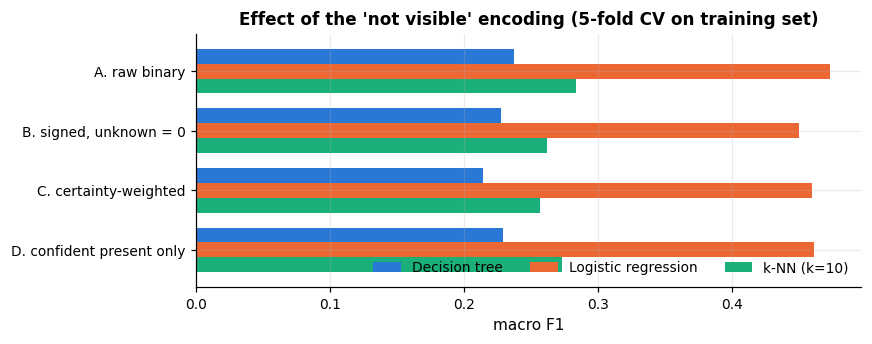

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.2))
encoding_results.plot.barh(ax=ax, color=[u.BLUE, u.ORANGE, u.AQUA], width=0.75)
ax.invert_yaxis()
ax.set(title="Effect of the 'not visible' encoding (5-fold CV on training set)",
       xlabel="macro F1", ylabel="")
ax.legend(loc="lower right", ncols=3)
plt.tight_layout()
u.save_figure(fig, "01_encoding_experiment")
plt.show()

**Figure 3** — The raw binary encoding (A) scores best or equal-best for all three classifiers.
Removing or down-weighting uncertain answers throws away information: even a "guess" or a "not visible"
answer is informative (e.g. wings that are *never* visible at rest are themselves typical of some species).

> **Decision 4 — "Not visible" labels.** Keep the **raw 0/1 attributes** (encoding A). The certainty and time
> columns are **not used as features**. The limitation (0 mixes "absent" and "unseen") is acknowledged in the report.

## 6. Duplicate rows with conflicting labels

If two images have exactly the same 312 attributes but **different species**, no model using only these attributes
can tell them apart — they are contradictory training examples (label noise). The pipeline flags such images in
`conflicting_duplicate`.

In [10]:
signature = df[ATTR].astype(str).agg("".join, axis=1)
is_dupe = signature.duplicated(keep=False)
dupes = df.loc[is_dupe, ["image_id", "species", "conflicting_duplicate"]].assign(signature=signature[is_dupe])

print(f"Images sharing their attribute vector with another image: {len(dupes)}")
print(f"  ...of which in groups with DIFFERENT species:            {df['conflicting_duplicate'].sum()}")
print(f"  ...in the training set:                                  "
      f"{df.loc[df['is_train'] == 1, 'conflicting_duplicate'].sum()}")

conflicts = (dupes[dupes["conflicting_duplicate"] == 1]
             .groupby("signature")
             .agg(n_images=("image_id", "size"),
                  species=("species", lambda s: ", ".join(sorted(set(s)))),
                  attributes_present=("image_id", lambda ids: int(df.loc[ids.index, ATTR].iloc[0].sum())))
             .sort_values("n_images", ascending=False)
             .reset_index(drop=True))
conflicts.head(10)

Images sharing their attribute vector with another image: 55
  ...of which in groups with DIFFERENT species:            39
  ...in the training set:                                  19


,n_images,species,attributes_present
0,6,"American Crow, Fish Crow, Shiny Cowbird",27
1,4,"American Crow, Fish Crow",27
2,3,"American Pipit, Bay breasted Warbler, Pomarine...",6
3,2,"Brewer Blackbird, Groove billed Ani",3
4,2,"Green Jay, Magnolia Warbler",3
5,2,"Blue winged Warbler, Orange crowned Warbler",5
6,2,"Black footed Albatross, Western Grebe",4
7,2,"Artic Tern, Western Grebe",5
8,2,"Pied billed Grebe, Western Grebe",6
9,2,"Mourning Warbler, Orange crowned Warbler",3


Two kinds of conflicts appear: (1) **genuine look-alikes** — the largest groups are all-black birds
(American Crow, Fish Crow, Shiny Cowbird) annotated identically; (2) **sparse annotations** — images where only
3–6 attributes were marked present, so very different birds end up with the same vector.

> **Decision 5 — Conflicting duplicates.** Remove the conflicting duplicates **from the training set only**.
> They teach contradictory labels (k-NN is hit hardest: a distance of 0 to a wrong species). The **test set is left
> untouched** so that results stay comparable with the official split and with other work on CUB.

## 7. Rare attributes

Some attributes are almost never present. Very rare features add dimensions but little information overall —
**however**, a rare feature can still be very informative for one particular species (the per-class view used in the lab).

In [11]:
prevalence = df[ATTR].mean().sort_values()
rare = prevalence[prevalence < 0.01]

# For each rare attribute: in which species is it most common, and how common is it there?
species_mean = df.groupby("species")[rare.index].mean()
rare_table = pd.DataFrame({
    "overall prevalence (%)":   (rare * 100).round(2),
    "most common in species":   species_mean.idxmax(),
    "prevalence there (%)":     (species_mean.max() * 100).round(1),
})
print(f"Attributes present in < 1% of images: {len(rare)} of {len(ATTR)}")
rare_table.sort_values("prevalence there (%)", ascending=False).head(10)

Attributes present in < 1% of images: 48 of 312


,overall prevalence (%),most common in species,prevalence there (%)
has_throat_color::green,0.97,Green Violetear,36.7
has_eye_color::blue,0.88,Brandt Cormorant,35.6
has_forehead_color::green,0.91,Green Violetear,28.3
has_under_tail_color::rufous,0.88,Summer Tanager,28.3
has_under_tail_color::green,0.98,Spotted Catbird,26.7
has_upper_tail_color::green,0.89,Spotted Catbird,24.4
has_back_color::rufous,0.89,Summer Tanager,23.3
has_upper_tail_color::rufous,0.69,Summer Tanager,21.7
has_crown_color::pink,0.53,Anna Hummingbird,20.0
has_forehead_color::pink,0.41,Anna Hummingbird,18.3


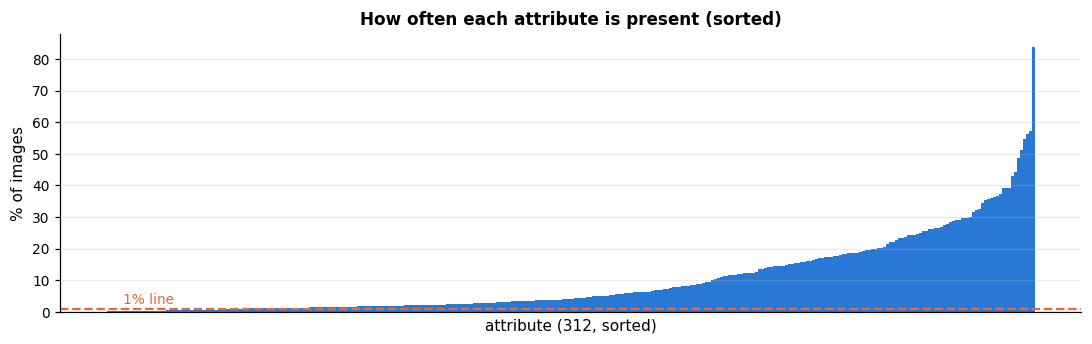

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(np.arange(len(prevalence)), prevalence.values * 100, width=1.0, color=u.BLUE)
ax.axhline(1, color=u.ORANGE, lw=1.5, ls="--")
ax.text(5, 2.5, "1% line", color=u.ORANGE)
ax.set(title="How often each attribute is present (sorted)", xlabel="attribute (312, sorted)",
       ylabel="% of images", xticks=[])
plt.tight_layout()
u.save_figure(fig, "01_attribute_prevalence")
plt.show()

**Figure 4** — Prevalence is very skewed: the median attribute is present in about 4% of images and 48 attributes
in fewer than 1%. The table shows that several rare attributes are concentrated in a few species,
so they can be highly informative for exactly those species.

> **Decision 6 — Rare attributes.** **Keep all 312 attributes** in the cleaned data. Removing features is a modelling
> choice, so it is done and evaluated in `03_feature_selection.ipynb` (which produces smaller feature sets for R3).

## 8. Do we need scaling, normalisation or binning?

Lecture 3 covers four preparation steps. We check each against the data type:

In [13]:
# Some attribute groups are single-choice (exactly one value per image), others multi-choice.
groups = pd.Series({c: u.attribute_group(c) for c in ATTR})
values_per_image = pd.DataFrame({g: df[cols.index].sum(axis=1) for g, cols in groups.groupby(groups)})

group_summary = pd.DataFrame({
    "n values":           groups.value_counts(),
    "min chosen / image": values_per_image.min(),
    "max chosen / image": values_per_image.max(),
}).sort_values("max chosen / image")
# single-choice groups (max 1) first, then the multi-choice colour groups
pd.concat([group_summary.head(8), group_summary.tail(4)])

,n values,min chosen / image,max chosen / image
breast_pattern,4,0,1
tail_pattern,4,0,1
tail_shape,6,0,1
wing_pattern,4,0,1
shape,14,1,1
bill_shape,9,0,1
size,5,1,1
belly_pattern,4,0,1
belly_color,15,0,4
primary_color,15,1,4


| Lecture 3 step | Needed? | Reason |
|---|---|---|
| Missing values | No imputation | No empty cells; "not visible" handled in Decision 4 |
| Instance normalisation | **No** | Values are presence flags, not counts (unlike the word-count example) |
| Feature scaling | **No** | Every feature is already on the same 0–1 scale; k-NN Euclidean distance on 0/1 data equals the square root of the number of mismatching attributes (Hamming distance) |
| Discretisation (binning) | **No** | Features are already discrete |

One structural note for R3: `shape` and `size` are **one-hot groups** (exactly one value per image), so their columns
always sum to 1. This makes them perfectly collinear for linear/logistic regression — regularisation (the default in
scikit-learn) handles this. Colour groups are multi-choice (a bird can have several primary colours).

> **Decision 7 — Transformations.** No scaling, normalisation or binning is applied to Dataset 1.

## 9. Dataset 2: image checks

The pipeline opened every image once and recorded its size and colour mode.

In [14]:
img_checks = {
    "Images listed":                              len(images),
    "Colour mode counts":                         images["mode"].value_counts().to_dict(),
    "Width range (px)":                           f'{images["width"].min()}–{images["width"].max()}',
    "Height range (px)":                          f'{images["height"].min()}–{images["height"].max()}',
    "Bounding boxes clipped to the image border": int(images["bbox_clipped"].sum()),
}
pd.Series(img_checks, name="result").to_frame()

,result
Images listed,11788
Colour mode counts,"{'RGB': 11780, 'L': 8}"
Width range (px),121–500
Height range (px),120–500
Bounding boxes clipped to the image border,8


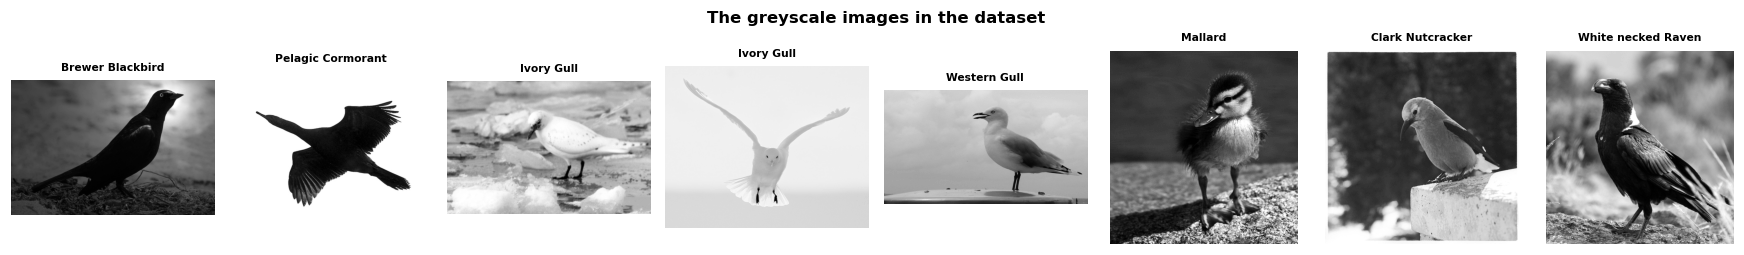

In [15]:
from PIL import Image

grey = images[images["mode"] != "RGB"]
fig, axes = plt.subplots(1, len(grey), figsize=(2.0 * len(grey), 2.3))
for ax, (_, row) in zip(np.atleast_1d(axes), grey.iterrows()):
    ax.imshow(Image.open(u.RAW_DIR / "images" / row["image_path"]), cmap="gray")
    ax.set_title(row["species"], fontsize=7)
    ax.axis("off")
fig.suptitle("The greyscale images in the dataset", fontweight="bold")
plt.tight_layout()
plt.show()

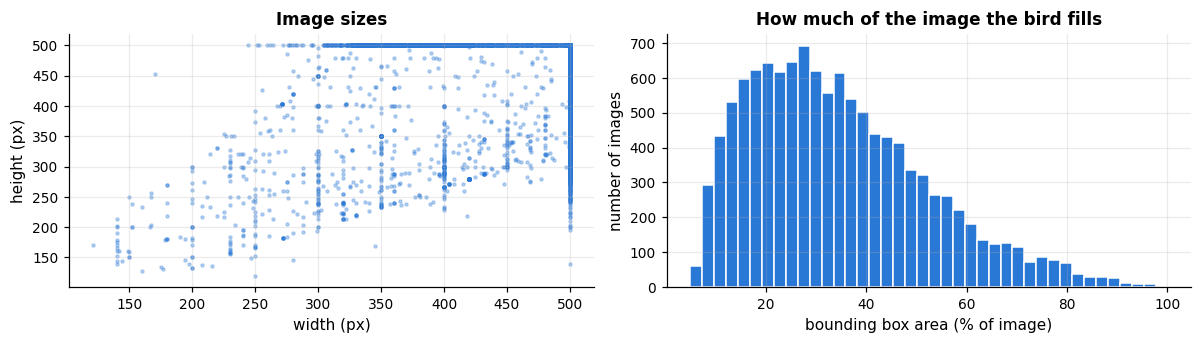

Median share of the image covered by the bird: 32%


In [16]:
images["bbox_area_share"] = (images["bbox_w"] * images["bbox_h"]) / (images["width"] * images["height"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].scatter(images["width"], images["height"], s=4, alpha=0.3, color=u.BLUE)
axes[0].set(title="Image sizes", xlabel="width (px)", ylabel="height (px)")
axes[1].hist(images["bbox_area_share"] * 100, bins=40, color=u.BLUE, edgecolor="white")
axes[1].set(title="How much of the image the bird fills", xlabel="bounding box area (% of image)",
            ylabel="number of images")
plt.tight_layout()
u.save_figure(fig, "01_image_sizes")
plt.show()
print(f"Median share of the image covered by the bird: {images['bbox_area_share'].median():.0%}")

**Figure 5** — Images vary in size (most are 500 px on the long side) and the bird often fills only part of the frame.

> **Decision 8 — Images.** No image is missing or corrupt, so all 11,788 are kept. For R4 the pipeline provides what is
> needed to (a) **convert the 8 greyscale images to RGB**, (b) **crop to the (clipped) bounding box** so the model sees the
> bird rather than the background, and (c) **resize to a fixed input size**. The exact size is an R4 modelling choice.

## 10. Cleaning log and saving the cleaned data

In [17]:
clean = df[~((df["is_train"] == 1) & (df["conflicting_duplicate"] == 1))].copy()

removed = len(df) - len(clean)
print(f"Rows before: {len(df):,} | removed (conflicting duplicates in train): {removed} | after: {len(clean):,}")
print(f"Train: {clean['is_train'].sum():,} | Test: {(clean['is_train'] == 0).sum():,}")
print(f"Training images per species after cleaning: "
      f"{clean[clean['is_train'] == 1].groupby('class_id').size().min()}–"
      f"{clean[clean['is_train'] == 1].groupby('class_id').size().max()}")

out_path = u.PROCESSED_DIR / "cub_attributes_clean.csv"
clean.to_csv(out_path, index=False)
print(f"Saved: {out_path.relative_to(u.REPO_ROOT)}")

Rows before: 11,788 | removed (conflicting duplicates in train): 19 | after: 11,769
Train: 5,975 | Test: 5,794
Training images per species after cleaning: 26–30


Saved: data\processed\cub_attributes_clean.csv


In [18]:
cleaning_log = pd.DataFrame([
    ("Integrity",            "No missing values, ids/labels/split consistent across both datasets", "No action"),
    ("Malformed lines",      "606 lines (2 images) with an extra field",                           "Repaired in pipeline; all images kept"),
    ("Class balance",        "41–60 images/species; train 29–30/species",                          "Keep 200 species + official split; report macro metrics"),
    ("'Not visible' labels", "10.7% of labels; stored as 0",                                        "Keep raw 0/1 (best in CV experiment); drop certainty/time"),
    ("Conflicting duplicates", f"{df['conflicting_duplicate'].sum()} images share vectors across species",
                                                                                                    f"Removed from train only ({removed} rows)"),
    ("Rare attributes",      f"{len(rare)} attributes present in < 1% of images",                  "Keep; evaluated in feature selection"),
    ("Scaling/normalisation/binning", "All features binary 0/1",                                    "Not needed"),
    ("Images",               "8 greyscale; 8 boxes past the border; sizes vary",                    "Convert to RGB, clip boxes, crop + resize in R4"),
], columns=["Issue", "Finding", "Decision"])
cleaning_log.index = range(1, len(cleaning_log) + 1)
cleaning_log

,Issue,Finding,Decision
1,Integrity,"No missing values, ids/labels/split consistent...",No action
2,Malformed lines,606 lines (2 images) with an extra field,Repaired in pipeline; all images kept
3,Class balance,41–60 images/species; train 29–30/species,Keep 200 species + official split; report macr...
4,'Not visible' labels,10.7% of labels; stored as 0,Keep raw 0/1 (best in CV experiment); drop cer...
5,Conflicting duplicates,39 images share vectors across species,Removed from train only (19 rows)
6,Rare attributes,48 attributes present in < 1% of images,Keep; evaluated in feature selection
7,Scaling/normalisation/binning,All features binary 0/1,Not needed
8,Images,8 greyscale; 8 boxes past the border; sizes vary,"Convert to RGB, clip boxes, crop + resize in R4"
